# ARTI403 – Image Processing
## Lab 6: Filtering in the Frequency Domain

This notebook covers:
1. **Task #1 (in-class demo):** Laplacian filtering of the Cameraman image in the frequency domain.
2. **Assessment Task #1:** Sobel filtering (horizontal & vertical) of the Cameraman image in the frequency domain.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift

## Task #1: Filtering in the Frequency Domain (Laplacian)

We load the Cameraman image, build a Laplacian filter directly in the frequency domain (using the frequency-grid formula $-4\pi^2(u^2+v^2)$), apply it to the image's FFT, and transform back to the spatial domain.

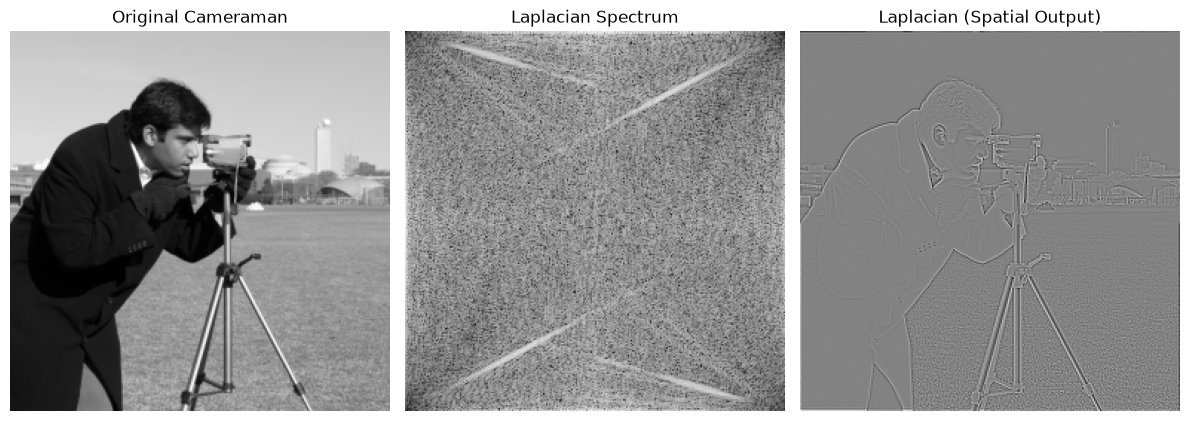

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

---
## Assessment Task #1: Sobel Filtering in the Frequency Domain

**Task:** Using the same Cameraman image, apply the Sobel filter(s) in the frequency domain and show the results.

**Approach:**
1. Load and resize the image (same as Task #1).
2. Define the $3\times3$ Sobel kernels for the horizontal ($G_x$) and vertical ($G_y$) gradients.
3. Zero-pad each kernel to the image size, centering it, then apply `ifftshift` before the FFT so the kernel's origin sits at the top-left (as required for frequency-domain convolution) — this is what `center_embed_kernel` below does.
4. Multiply the image's FFT by each kernel's FFT (pointwise multiplication in the frequency domain = convolution in the spatial domain).
5. Apply the inverse FFT to get the spatial-domain gradient images, then combine them into the gradient magnitude.

In [3]:
# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                     [-2, 0, 2],
                     [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                     [ 0,  0,  0],
                     [ 1,  2,  1]])

In [4]:
# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape

    # Find center coordinates
    cy, cx = ph // 2, pw // 2

    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel

    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

In [5]:
# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Sx_f = center_embed_kernel(sobel_x, (M, N))
Sy_f = center_embed_kernel(sobel_y, (M, N))

# Multiply in the frequency domain
Gx_f = F * Sx_f
Gy_f = F * Sy_f

# Inverse FFT back to the spatial domain
gx = ifft2(Gx_f).real
gy = ifft2(Gy_f).real

# Gradient magnitude combines both directions
gradient_magnitude = np.sqrt(gx**2 + gy**2)

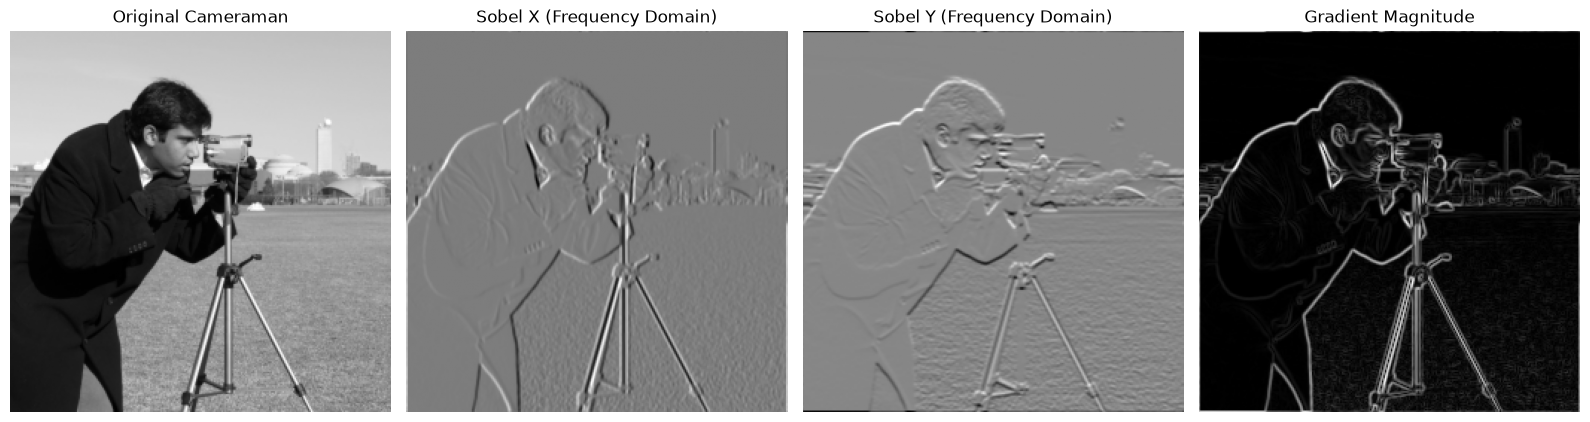

In [6]:
# Plot
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(gx, cmap='gray')
plt.title('Sobel X (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(gy, cmap='gray')
plt.title('Sobel Y (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(gradient_magnitude, cmap='gray')
plt.title('Gradient Magnitude')
plt.axis('off')

plt.tight_layout()
plt.show()

### Optional: magnitude spectra of the Sobel filters

Just like the Laplacian spectrum shown in Task #1, we can visualize the frequency-domain representation of each Sobel filter.

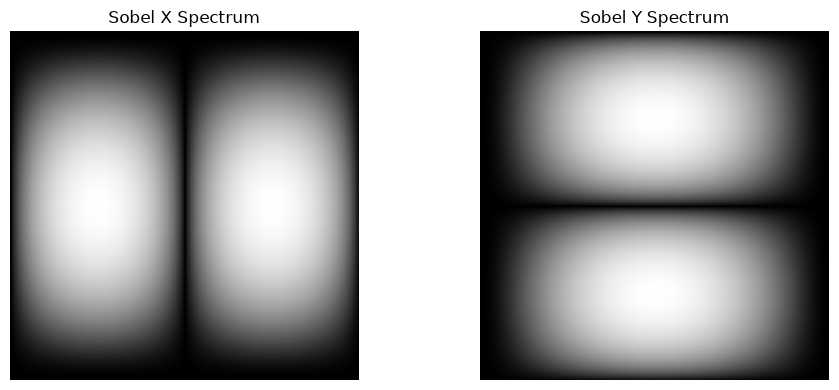

In [7]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.log(1 + np.abs(np.fft.fftshift(Sx_f))), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(np.log(1 + np.abs(np.fft.fftshift(Sy_f))), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.tight_layout()
plt.show()

### Observations

- `sobel_x` responds to **vertical edges** (horizontal intensity change), and `sobel_y` responds to **horizontal edges** (vertical intensity change) — same behavior as spatial-domain convolution, since multiplying FFTs is mathematically equivalent to convolving in the spatial domain.
- The **gradient magnitude** combines both directions and highlights edges in the image regardless of orientation (the tripod, the camera, the outline of the man, and the building in the background all stand out clearly).
- Centering the kernel in a zero-padded array and applying `ifftshift` before the FFT is what places the kernel's origin at frequency-grid index `(0,0)`, matching the convention of `np.fft.fft2`, so the convolution theorem applies correctly (no circular-shift artifacts).